### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 72

def grad_mag(img):
    return np.hypot(cv2.Sobel(img, cv2.CV_64F, 1, 0), cv2.Sobel(img, cv2.CV_64F, 0, 1))

def show_grid(images, titles, ncols=None, size=4, cmap='gray', **kw):
    ncols = ncols or len(images)
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    _, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * h / w + 0.7 * nrows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, img, title in zip(axes.ravel(), images, titles):
        ax.imshow(img, cmap=cmap, **kw); ax.set_title(title)
    plt.show()

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

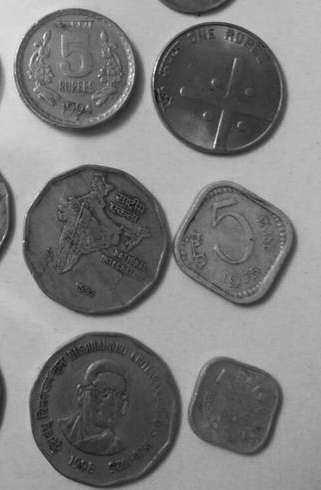

In [3]:
coins = cv2.imread('Monety_szare.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins)

Rozwiązanie:

In [4]:
N_FULL = 6

def find_objects(edges, min_area=3000):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(255 - edges, connectivity=4)
    border = set(np.r_[labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    keep = [i for i in range(1, n) if i not in border and stats[i, cv2.CC_STAT_AREA] >= min_area]
    objects = np.zeros_like(labels)
    for k, i in enumerate(keep, 1):
        objects[labels == i] = k
    return objects, len(keep)

**1.1 Moduł gradientu (Sobel 3×3), mapa ciepła.**

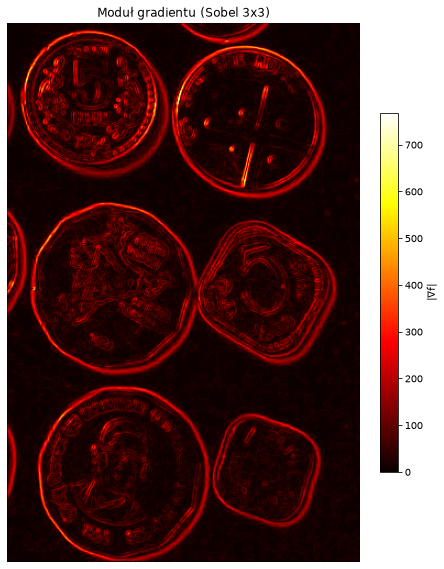

|∇f| < 2% maks.: 45% pikseli, |∇f| < 5% maks.: 70% pikseli, |∇f| < 10% maks.: 83% pikseli


In [5]:
g = grad_mag(coins)
plt.figure(figsize=(7, 10))
plt.imshow(g, cmap='hot'); plt.colorbar(label='|∇f|', fraction=0.046)
plt.title('Moduł gradientu (Sobel 3x3)'); plt.axis('off'); plt.show()
print(', '.join(f'|∇f| < {f:.0%} maks.: {(g < f * g.max()).mean():.0%} pikseli' for f in (0.02, 0.05, 0.10)))

**1.2 Czy sam gradient pozwala wykryć obiekty?** Próg |∇f| od bardzo niskiego (połowa pikseli to „krawędź”) do bardzo wysokiego (1% pikseli), w tym automatyczny próg Otsu. Obiekt = obszar otoczony „krawędzią”, czyli składowa spójna tła, która nie dotyka brzegu obrazu (`connectedComponentsWithStats`, jak w lab 1).

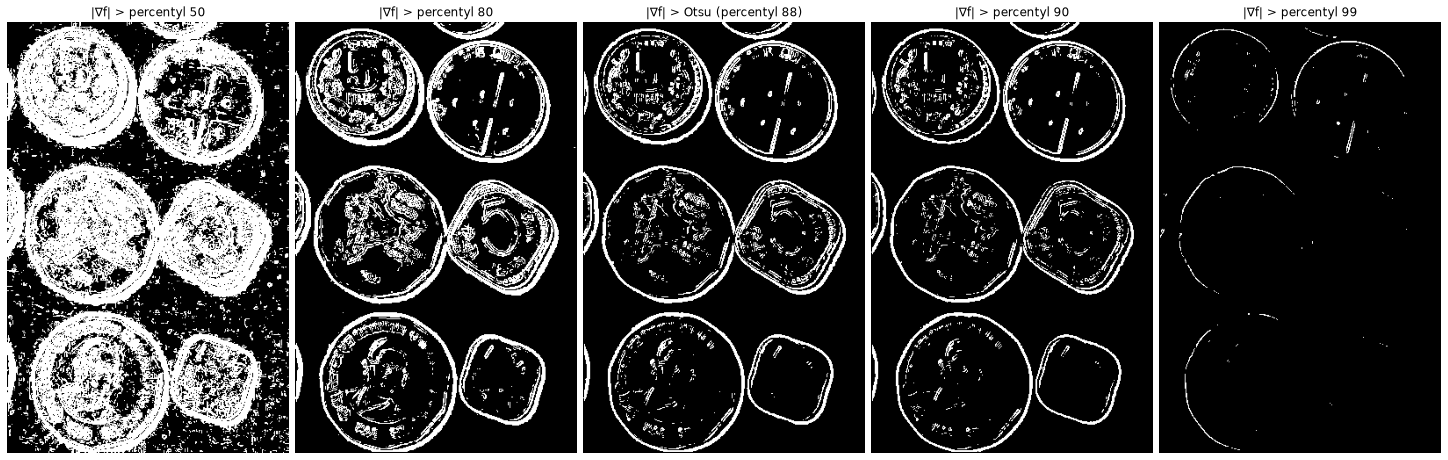

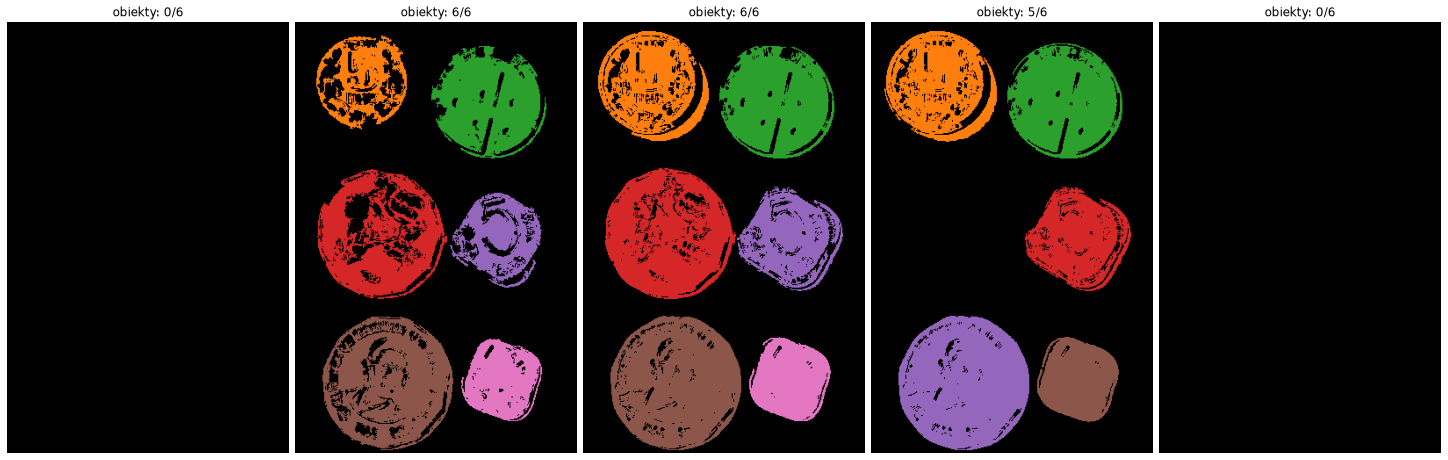

In [6]:
g8 = (g / g.max() * 255).astype(np.uint8)
t_otsu, mask_otsu = cv2.threshold(g8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
masks = {f'percentyl {p}': ((g > np.percentile(g, p)) * 255).astype(np.uint8) for p in [50, 80]}
masks[f'Otsu (percentyl {100 * (g8 <= t_otsu).mean():.0f})'] = mask_otsu
masks |= {f'percentyl {p}': ((g > np.percentile(g, p)) * 255).astype(np.uint8) for p in [90, 99]}
objects = [find_objects(m) for m in masks.values()]
show_grid(list(masks.values()), [f'|∇f| > {name}' for name in masks])
show_grid([plt.cm.tab10(o % 10)[..., :3] * (o > 0)[..., None] for o, _ in objects], [f'obiekty: {n}/{N_FULL}' for _, n in objects])

**Wnioski (zad. 1)**
- **Gdzie gradient ≈ 0?** Na jednolitym tle i w płaskich polach monet: 45% pikseli ma |∇f| poniżej 2% maksimum, 83% poniżej 10%. Duże wartości dają zewnętrzne kontury, ale też relief monet (cyfry, napisy, rant) i cień.
- **Czy to wystarczy do detekcji?** Sam gradient to mapa konturów, nie maska obiektów: obiektami są dopiero obszary otoczone konturem. Przy progu na 80. percentylu i przy automatycznym progu Otsu (88. percentyl) wychodzi 6/6 monet, a stykające się monety są rozdzielone, bo każda ma własne wnętrze. Okno dobrych progów jest wąskie: przy 90. percentylu kontur jednej monety ma przerwę, jej wnętrze łączy się z tłem i zostaje 5/6. Skrajności: przy 50. percentylu „krawędzią” jest prawie wszystko, przy 99. kontury rozpadają się na kawałki. W obu przypadkach nie powstaje ani jeden zamknięty obiekt.

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

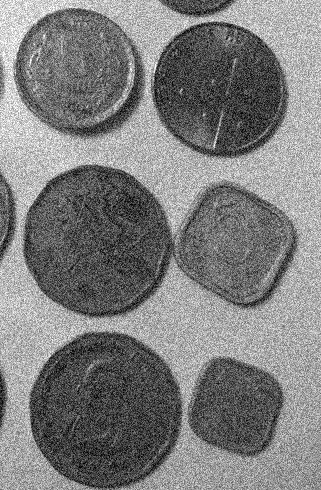

In [7]:
coins_noise = cv2.imread('Monety_szare_szum.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins_noise)

Rozwiązanie:

**Wzorzec konturów monet** (do oceny krawędzi w zad. 2 i 3): Otsu na *czystym* obrazie po silnym rozmyciu i kontur tej maski. **F1** = zgodność krawędzi z konturem wzorca, z tolerancją 2 px.

In [8]:
_, gt_mask = cv2.threshold(cv2.medianBlur(coins, 15), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
gt_edges = cv2.Canny(gt_mask, 100, 200)

TOL = 2

def near(edges):
    return cv2.blur(edges, (2 * TOL + 1, 2 * TOL + 1)) > 0

def edge_f1(edges):
    e = edges > 0
    precision = (e & near(gt_edges)).sum() / max(e.sum(), 1)
    recall = ((gt_edges > 0) & near(edges)).sum() / (gt_edges > 0).sum()
    return 2 * precision * recall / max(precision + recall, 1e-9)

**2.1 Progi Canny'ego bez odszumiania:** od skrajnie niskich do skrajnie wysokich, plus dwie pary pokazujące osobno rolę progu dolnego i górnego.

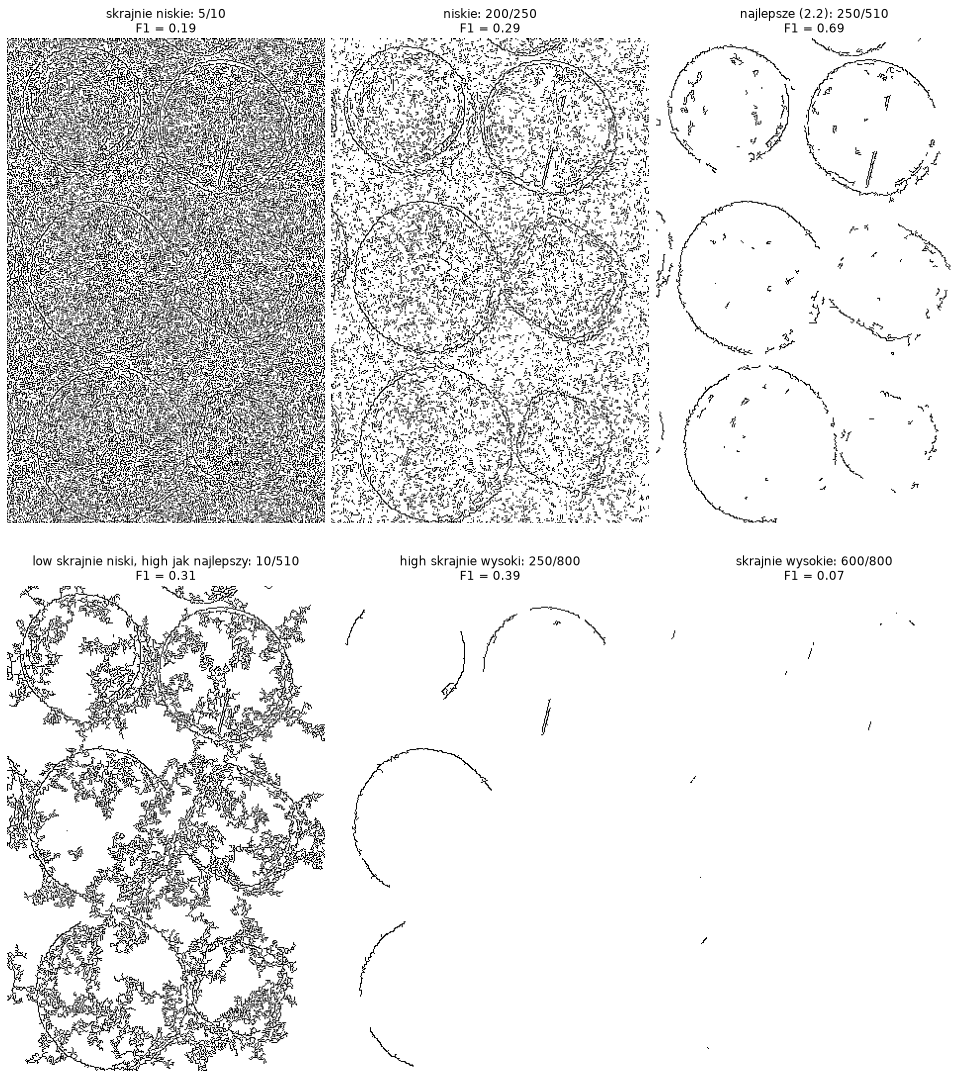

In [9]:
pairs = {'skrajnie niskie': (5, 10), 'niskie': (200, 250), 'najlepsze (2.2)': (250, 510),
         'low skrajnie niski, high jak najlepszy': (10, 510), 'high skrajnie wysoki': (250, 800), 'skrajnie wysokie': (600, 800)}
edges = {name: cv2.Canny(coins_noise, lo, hi) for name, (lo, hi) in pairs.items()}
show_grid(list(edges.values()), [f'{name}: {lo}/{hi}\nF1 = {edge_f1(e):.2f}' for (name, (lo, hi)), e in zip(pairs.items(), edges.values())],
          ncols=3, size=4.5, cmap='gray_r')

**2.2 Mapy F1 po siatce progów** dla czterech wariantów redukcji szumu (w tym filtr bilateralny, który wygładza z zachowaniem krawędzi). Gwiazdka = najlepsza para progów.

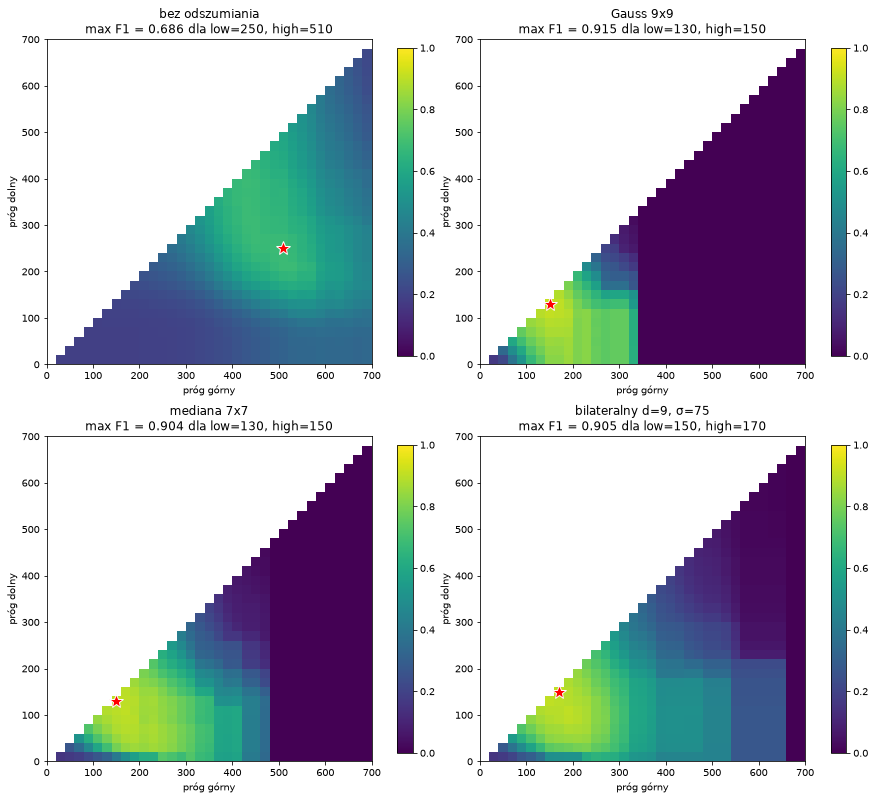

In [10]:
T = np.arange(10, 701, 20)

def canny_scan(src, metric=edge_f1, thresholds=T):
    out = np.full((len(thresholds), len(thresholds)), np.nan)
    for i, lo in enumerate(thresholds):
        for j in range(i + 1, len(thresholds)):
            out[i, j] = metric(cv2.Canny(src, lo, thresholds[j]))
    return out

def best(scan, thresholds=T):
    i, j = np.unravel_index(np.nanargmax(scan), scan.shape)
    return scan[i, j], thresholds[i], thresholds[j]

def scan_ax(ax, scan, title, thresholds=T):
    d = thresholds[1] - thresholds[0]
    im = ax.imshow(scan, origin='lower', extent=(thresholds[0] - d / 2, thresholds[-1] + d / 2) * 2, vmin=0, vmax=1)
    v, lo, hi = best(scan, thresholds)
    ax.plot(hi, lo, 'r*', ms=15, mec='w')
    ax.set_title(f'{title}\nmax F1 = {v:.3f} dla low={lo}, high={hi}'); ax.set_xlabel('próg górny'); ax.set_ylabel('próg dolny')
    plt.colorbar(im, ax=ax, fraction=0.046)

variants = {'bez odszumiania': coins_noise, 'Gauss 9x9': cv2.GaussianBlur(coins_noise, (9, 9), 0), 'mediana 7x7': cv2.medianBlur(coins_noise, 7),
            'bilateralny d=9, σ=75': cv2.bilateralFilter(coins_noise, 9, 75, 75)}
f1_scans = {name: canny_scan(img) for name, img in variants.items()}
_, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
for ax, (name, scan) in zip(axes.ravel(), f1_scans.items()):
    scan_ax(ax, scan, name)
plt.show()

**2.3 Siła odszumiania:** najlepsze F1 (przy najlepszych progach) w funkcji rozmiaru okna filtra, od 3×3 do skrajnego 61×61. Pod wykresem: obraz i krawędzie dla okna małego, optymalnego i skrajnie dużego.

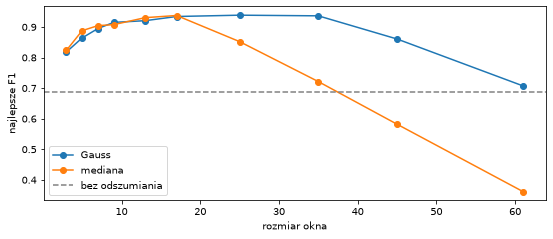

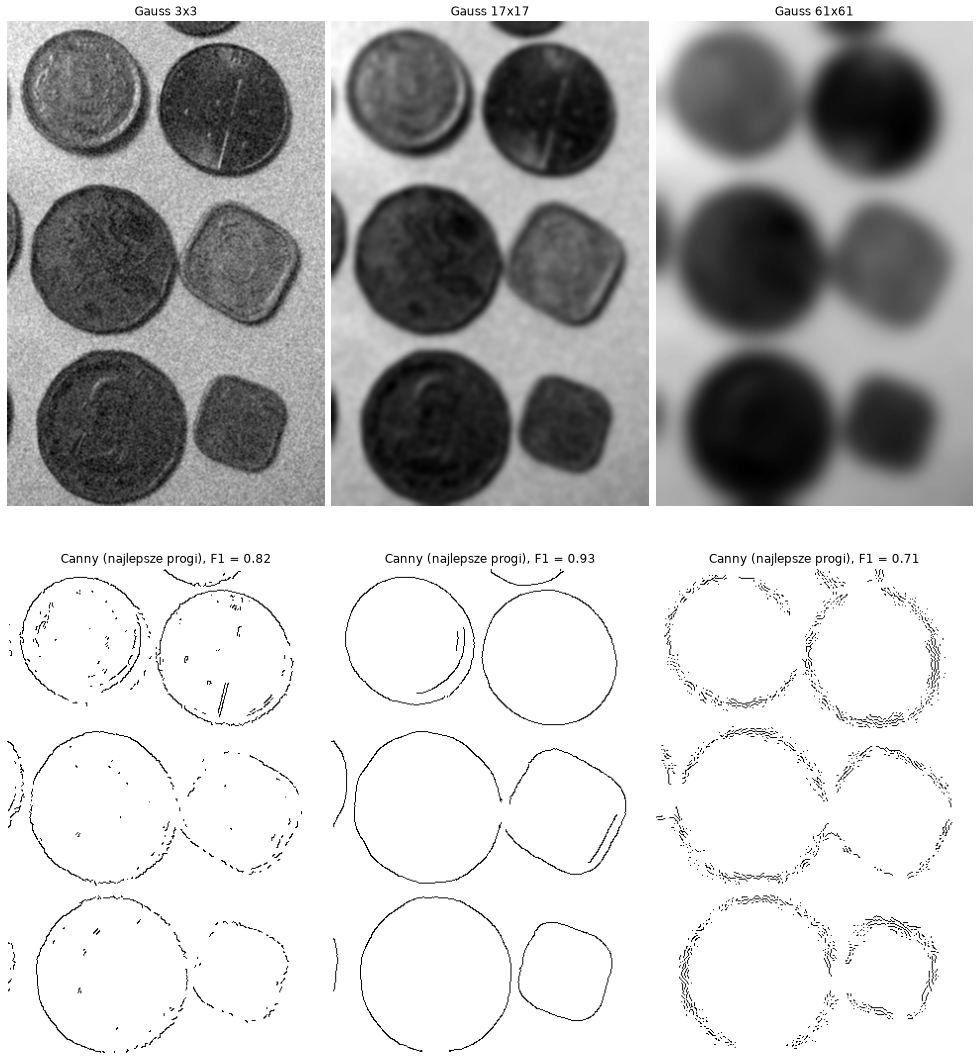

In [11]:
windows = [3, 5, 7, 9, 13, 17, 25, 35, 45, 61]
denoisers = {'Gauss': lambda img, k: cv2.GaussianBlur(img, (k, k), 0), 'mediana': lambda img, k: cv2.medianBlur(img, k)}
plt.figure(figsize=(9, 3.5))
for name, f in denoisers.items():
    plt.plot(windows, [best(canny_scan(f(coins_noise, k)))[0] for k in windows], 'o-', label=name)
plt.axhline(best(f1_scans['bez odszumiania'])[0], color='gray', ls='--', label='bez odszumiania')
plt.xlabel('rozmiar okna'); plt.ylabel('najlepsze F1'); plt.legend(); plt.show()

shown = {}
for k in [3, 17, 61]:
    img = cv2.GaussianBlur(coins_noise, (k, k), 0)
    f1, lo_k, hi_k = best(canny_scan(img))
    shown[k] = (img, cv2.Canny(img, lo_k, hi_k), f1)
show_grid([img for img, _, _ in shown.values()] + [255 - e for _, e, _ in shown.values()],
          [f'Gauss {k}x{k}' for k in shown] + [f'Canny (najlepsze progi), F1 = {f1:.2f}' for _, _, f1 in shown.values()], ncols=3, size=4.5)

**Wnioski (zad. 2)**
- **Bez odszumiania** progi stoją przed wyborem między dwiema złymi opcjami. Skrajnie niskie progi dają „spaghetti” z szumu (F1 0.19), skrajnie wysokie zostawiają pojedyncze fragmenty konturów. Sam skrajnie niski `low` przy dobrym `high` też psuje wynik, bo histereza „dociąga” szum podłączony do konturów. Najlepsze F1 to tylko 0.69 (low=250, high=510).
- **Po odszumieniu** optimum przesuwa się do niskich progów (Gauss 9×9: 130/150, F1 = 0.92), a obszar dobrych progów jest szeroki. Silniejsze odszumianie = niższe optymalne progi, bo rozmycie obniża też gradient na konturach.
- **Filtr bilateralny** (d=9, σ=75) daje F1 = 0.905 (150/170), trochę mniej niż Gauss 9×9 (0.915), mimo że ma zachowywać krawędzie. Szum ma odchylenie ≈ 26 poziomów, więc żeby go wygładzić, σ koloru musi być duże, a wtedy filtr uśrednia też przez kontury i działa prawie jak zwykły Gauss.
- **Siła odszumiania:** Oba filtry dochodzą do F1 ≈ 0.94 (Gauss 25×25, mediana 17×17), ale Gauss utrzymuje F1 > 0.90 w szerszym zakresie okien (9–35, mediana tylko 7–17). Szum jest gaussowski, a nie typu sól-pieprz, więc mediana nie ma przewagi. Skrajnie duże okno (61×61) rozmywa same monety: Gauss spada do 0.71 (prawie jak bez odszumiania), a mediana do 0.36, bo „zjada” zaokrąglone brzegi i rogi monet.

---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

Rozwiązanie:

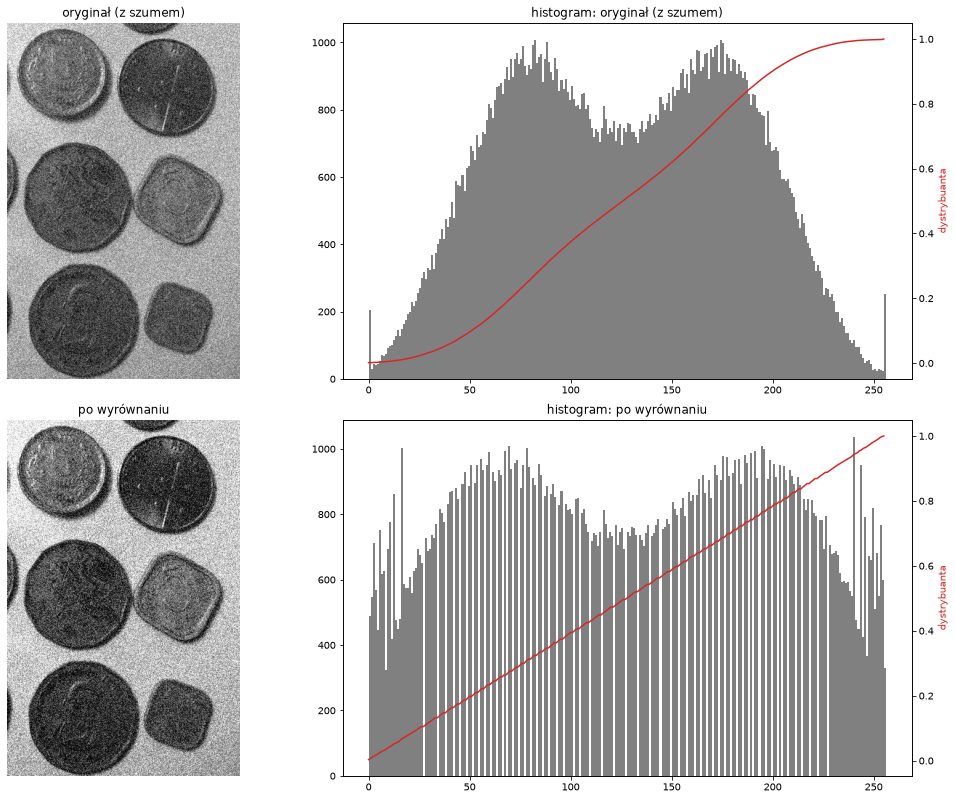

In [12]:
eq = cv2.equalizeHist(coins_noise)

_, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True, gridspec_kw={'width_ratios': [1, 1.6]})
for row, (name, img) in enumerate([('oryginał (z szumem)', coins_noise), ('po wyrównaniu', eq)]):
    axes[row, 0].imshow(img, cmap='gray', vmin=0, vmax=255); axes[row, 0].set_title(name); axes[row, 0].axis('off')
    axes[row, 1].hist(img.ravel(), 256, range=(0, 256), color='gray'); axes[row, 1].set_title(f'histogram: {name}')
    tw = axes[row, 1].twinx(); tw.plot(np.cumsum(np.bincount(img.ravel(), minlength=256)) / img.size, 'tab:red'); tw.set_ylabel('dystrybuanta', color='tab:red')
plt.show()

**Powtórka detekcji krawędzi z zad. 2 dla obrazu wyrównanego:** mapy F1 dla oryginału i obrazu wyrównanego.

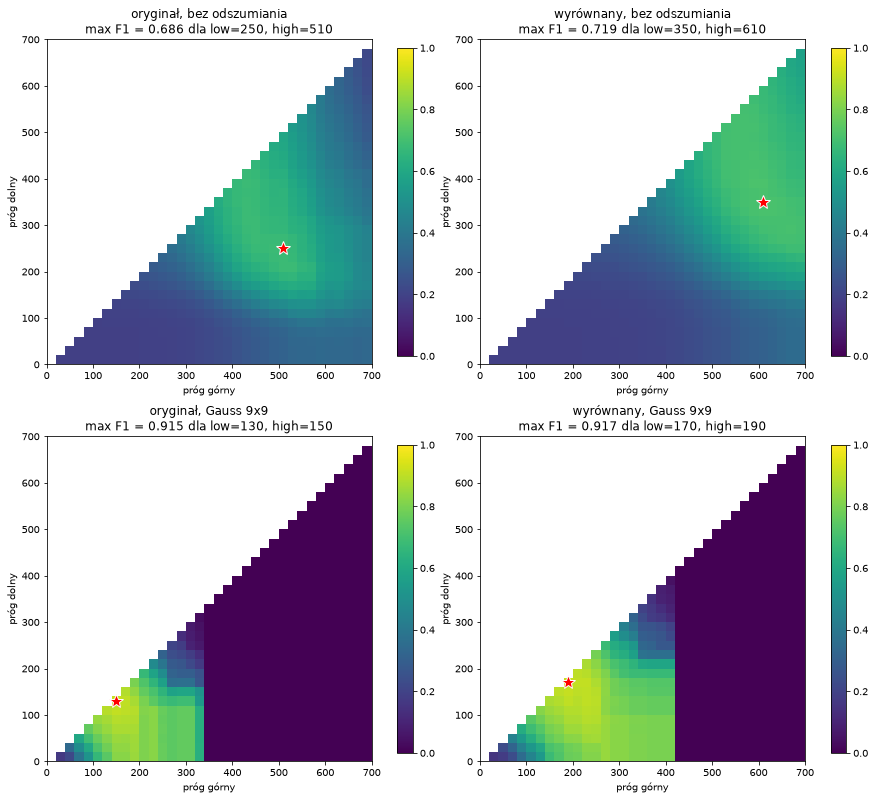

In [13]:
gauss9 = lambda img: cv2.GaussianBlur(img, (9, 9), 0)
_, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
for row, (name, f) in enumerate([('bez odszumiania', lambda img: img), ('Gauss 9x9', gauss9)]):
    scan_ax(axes[row, 0], f1_scans[name], f'oryginał, {name}')
    scan_ax(axes[row, 1], canny_scan(f(eq)), f'wyrównany, {name}')
plt.show()

**Wnioski (zad. 3)**
- Histogram obrazu z szumem jest już szeroki, więc wyrównanie zmienia go niewiele. Po wyrównaniu histogram ma „grzebień” (puste koszyki), bo LUT tylko rozsuwa lub skleja istniejące poziomy jasności.
- **Detekcja krawędzi:** wyrównanie praktycznie nie zmienia najlepszego F1 (bez odszumiania 0.69 → 0.72, z Gaussem 0.915 → 0.917), przesuwa tylko optymalne progi w górę, bo rozciąga kontrast. Canny reaguje na różnice jasności względem szumu, a globalna monotoniczna transformacja skaluje jedno i drugie.

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

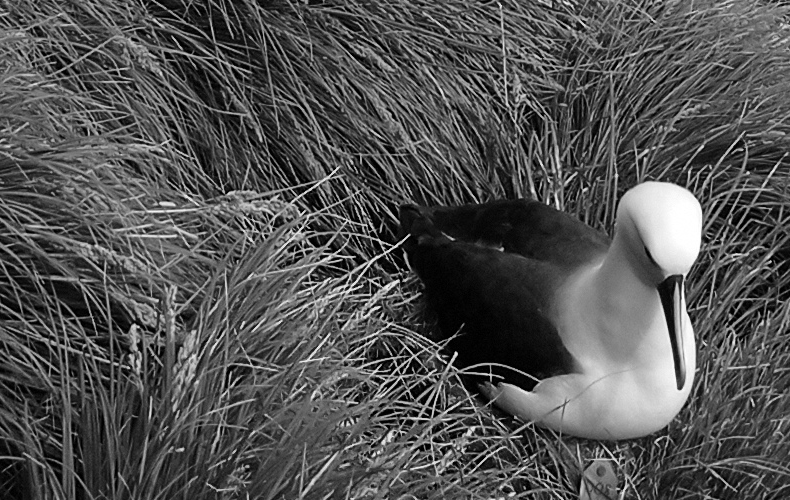

In [14]:
albatross_single = cv2.imread('albatross_single.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_single)

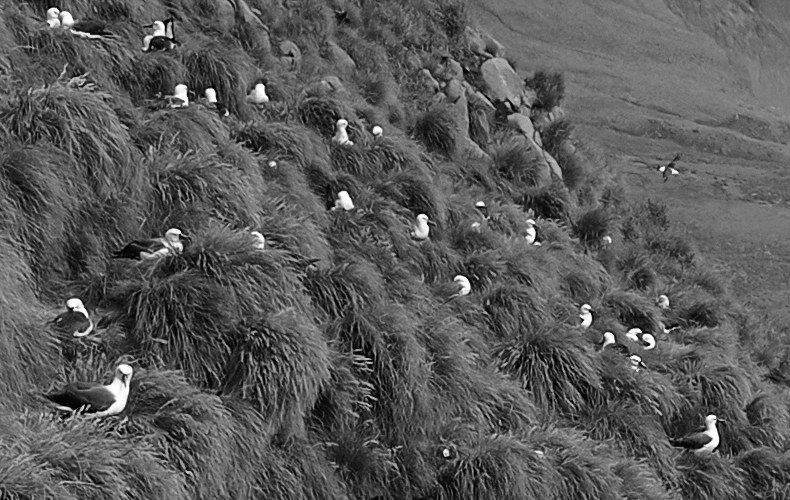

In [15]:
albatross_crowd = cv2.imread('albatross_crowd.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_crowd)

Rozwiązanie:

**Implementacja.** Dla każdego poziomu `l` obrazu wybieram najmniejszy poziom celu, którego dystrybuanta jest ≥ dystrybuanty obrazu w `l` (porównanie dystrybuant, bez `cv2.equalizeHist`), i nakładam LUT przez `cv2.LUT`.

Rozkład docelowy to mieszanina dwóch Gaussów: `w` = waga jasnego modu (obiekty), `delta` = odległość modów, `sigma` = szerokość modów, `center` = środek między modami.

In [16]:
L = np.arange(256)

def gauss_pdf(mu, sigma):
    p = np.exp(-0.5 * ((L - mu) / sigma) ** 2)
    return p / p.sum()

def bimodal(w=0.05, center=128, delta=140, sigma=20):
    return (1 - w) * gauss_pdf(center - delta / 2, sigma) + w * gauss_pdf(center + delta / 2, sigma)

def match_histogram(img, target_pdf):
    cdf_src = np.cumsum(np.bincount(img.ravel(), minlength=256)) / img.size
    cdf_tgt = np.cumsum(target_pdf) / np.sum(target_pdf)
    lut = np.searchsorted(cdf_tgt, cdf_src - 1e-9).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def otsu_report(img, target_pdf=None):
    out = match_histogram(img, target_pdf) if target_pdf is not None else img
    t, mask = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return dict(img=out, mask=mask, t=t, fg=(mask > 0).mean())

**4.1 Kształt rozkładu docelowego:** obraz po transformacji, osiągnięty histogram (szary) z rozkładem docelowym (czerwony) i progiem Otsu, maska Otsu.

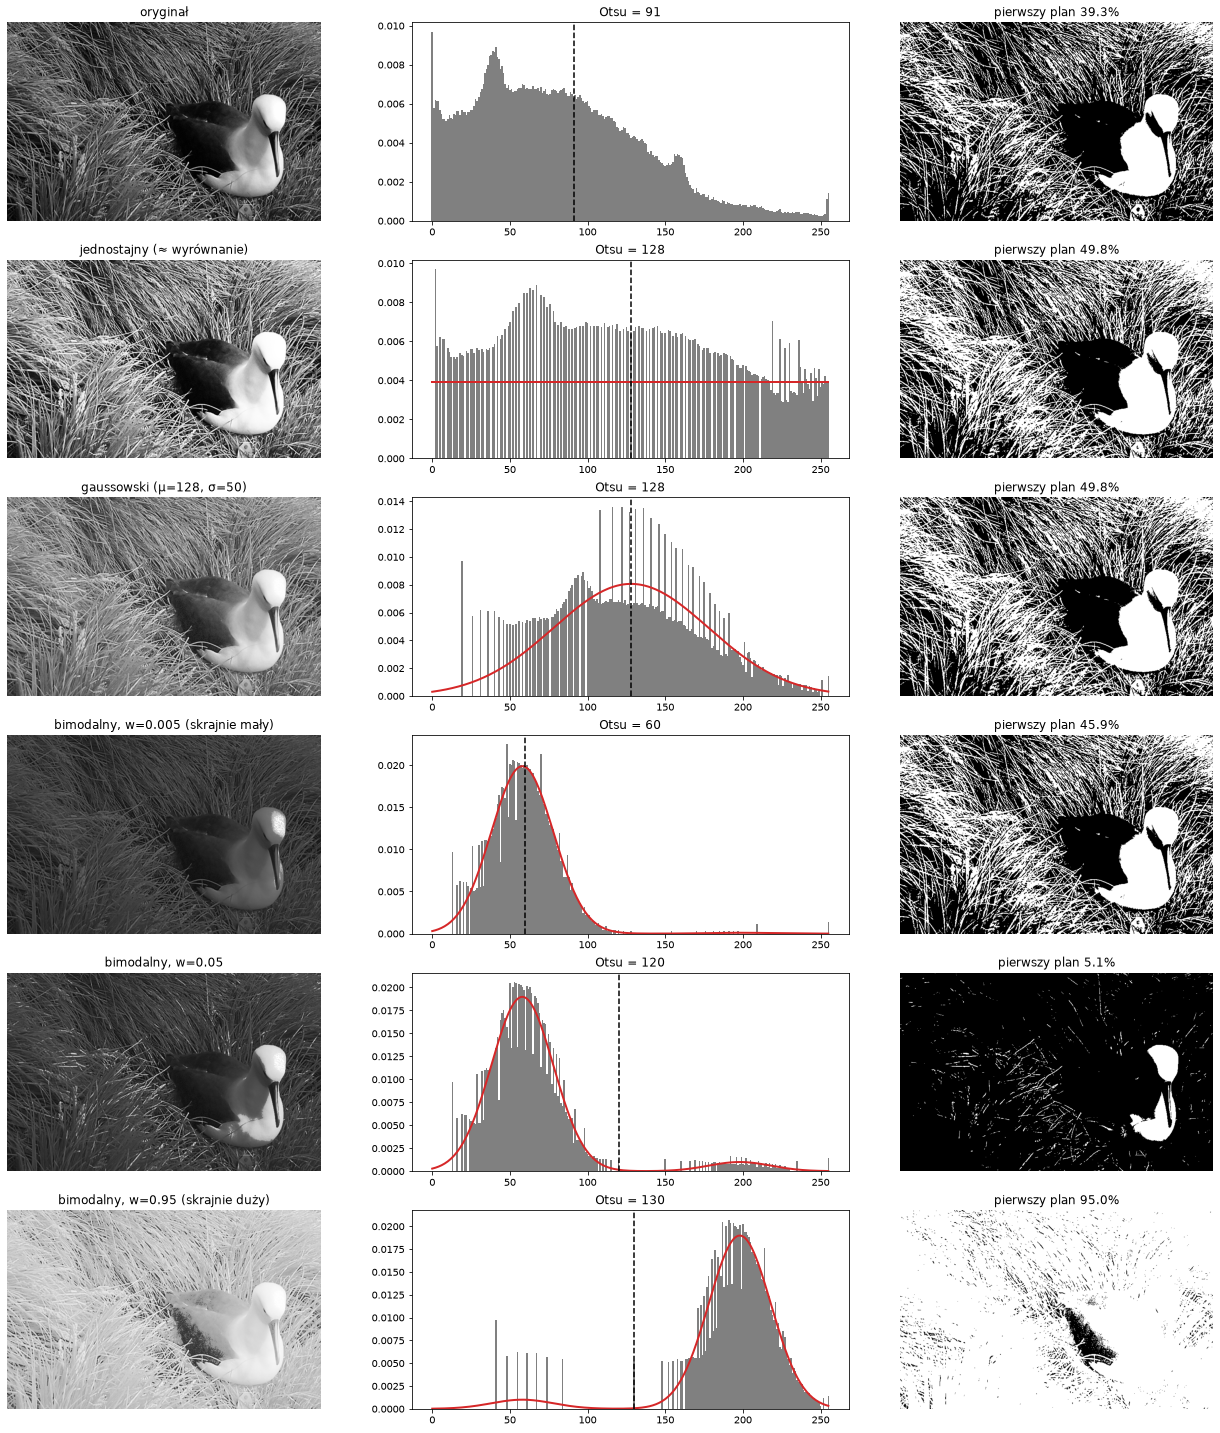

In [17]:
base = otsu_report(albatross_single)
targets = {'jednostajny (≈ wyrównanie)': np.ones(256), 'gaussowski (μ=128, σ=50)': gauss_pdf(128, 50), 'bimodalny, w=0.005 (skrajnie mały)': bimodal(w=0.005),
           'bimodalny, w=0.05': bimodal(w=0.05), 'bimodalny, w=0.95 (skrajnie duży)': bimodal(w=0.95)}
rows = {'oryginał': (None, base)} | {name: (pdf, otsu_report(albatross_single, pdf)) for name, pdf in targets.items()}
_, axes = plt.subplots(len(rows), 3, figsize=(18, 3.3 * len(rows)), constrained_layout=True, gridspec_kw={'width_ratios': [1, 1.1, 1]})
for (name, (pdf, r)), (a1, a2, a3) in zip(rows.items(), axes):
    a1.imshow(r['img'], cmap='gray', vmin=0, vmax=255); a1.set_title(name); a1.axis('off')
    a2.bar(L, np.bincount(r['img'].ravel(), minlength=256) / r['img'].size, width=1, color='gray')
    if pdf is not None:
        a2.plot(L, pdf / pdf.sum(), 'tab:red', lw=2)
    a2.axvline(r['t'], color='k', ls='--'); a2.set_title(f'Otsu = {r["t"]:.0f}')
    a3.imshow(r['mask'], cmap='gray'); a3.set_title(f'pierwszy plan {100 * r["fg"]:.1f}%'); a3.axis('off')
plt.show()

**4.2 Wpływ każdego parametru osobno**, od wartości skrajnie małych do skrajnie dużych (pozostałe stałe: w=0.05, center=128, delta=140, sigma=20). Na osi Y udział pierwszego planu: jeśli Otsu tnie w dolinie między modami, wynosi on `w` (zielona linia); szara linia = Otsu na oryginale. Pod wykresami maski dla kilku `w` i dla zlanych modów.

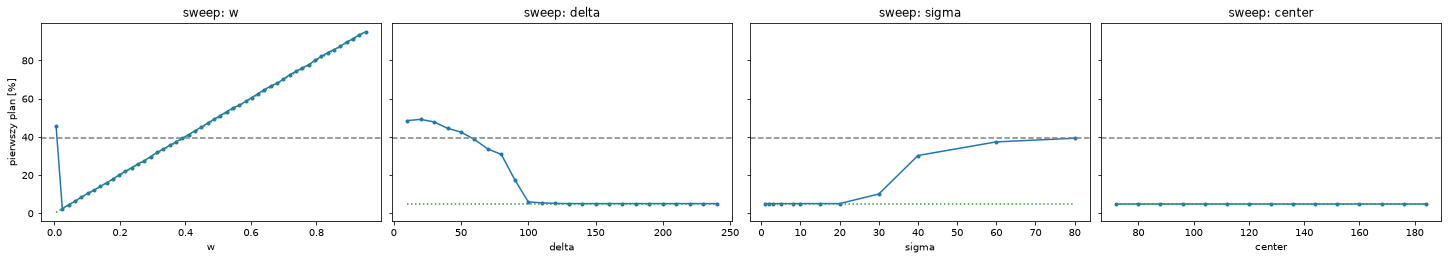

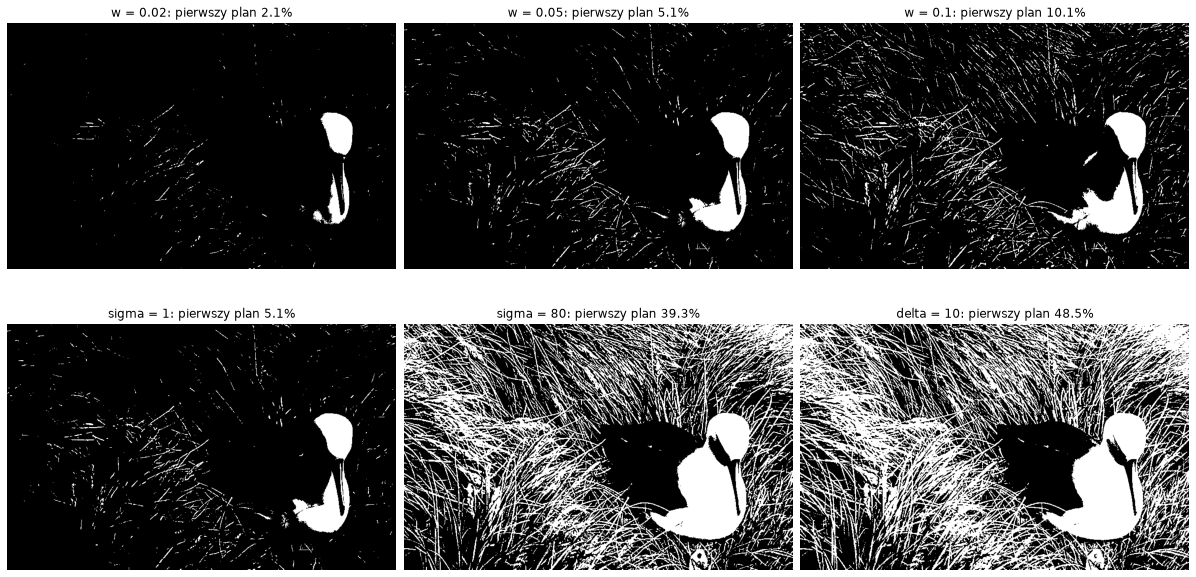

In [18]:
BASE = dict(w=0.05, center=128, delta=140, sigma=20)
sweeps = {
    'w': np.round(np.linspace(0.005, 0.95, 50), 3),
    'delta': np.arange(10, 241, 10),
    'sigma': np.array([1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 60, 80]),
    'center': np.arange(72, 185, 8),
}
_, axes = plt.subplots(1, len(sweeps), figsize=(20, 3.5), sharey=True, constrained_layout=True)
for ax, (p, vals) in zip(axes, sweeps.items()):
    ax.plot(vals, [100 * otsu_report(albatross_single, bimodal(**(BASE | {p: v})))['fg'] for v in vals], 'o-', ms=3)
    ax.plot(vals, 100 * (vals if p == 'w' else np.full(len(vals), BASE['w'])), color='tab:green', ls=':')
    ax.axhline(100 * base['fg'], color='gray', ls='--')
    ax.set_xlabel(p); ax.set_title(f'sweep: {p}')
axes[0].set_ylabel('pierwszy plan [%]'); plt.show()

extremes = [('w', 0.02), ('w', 0.05), ('w', 0.1), ('sigma', 1), ('sigma', 80), ('delta', 10)]
reports = [otsu_report(albatross_single, bimodal(**(BASE | {p: v}))) for p, v in extremes]
show_grid([r['mask'] for r in reports], [f'{p} = {v}: pierwszy plan {100 * r["fg"]:.1f}%' for (p, v), r in zip(extremes, reports)], ncols=3, size=5.5)

**4.3 `albatross_crowd`.** Liczba wykrytych obiektów (składowe 20–1500 px) w funkcji `w`; na powiększonym zdjęciu naliczyłem ok. 30 ptaków.

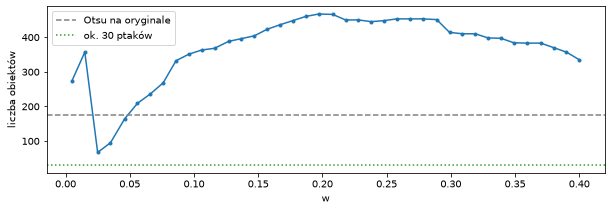

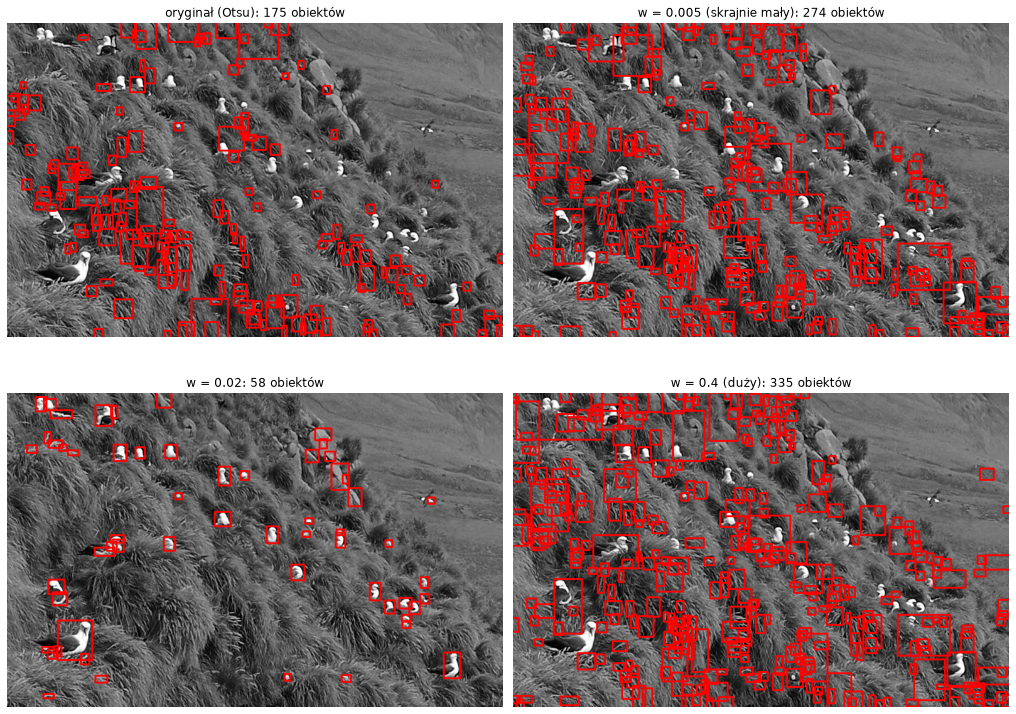

In [19]:
def count_birds(mask, min_area=20, max_area=1500):
    stats = cv2.connectedComponentsWithStats(mask)[2][1:]
    area = stats[:, cv2.CC_STAT_AREA]
    return stats[(area >= min_area) & (area <= max_area)]

def draw_birds(img, mask):
    rgb = np.dstack([img] * 3)
    for x, y, w, h, _ in count_birds(mask):
        cv2.rectangle(rgb, (x - 2, y - 2), (x + w + 2, y + h + 2), (255, 0, 0), 2)
    return rgb

ws = np.round(np.linspace(0.005, 0.4, 40), 3)
crowd_base = otsu_report(albatross_crowd)
plt.figure(figsize=(10, 3))
plt.plot(ws, [len(count_birds(otsu_report(albatross_crowd, bimodal(**(BASE | {'w': w})))['mask'])) for w in ws], 'o-', ms=3)
plt.axhline(len(count_birds(crowd_base['mask'])), color='gray', ls='--', label='Otsu na oryginale')
plt.axhline(30, color='tab:green', ls=':', label='ok. 30 ptaków')
plt.xlabel('w'); plt.ylabel('liczba obiektów'); plt.legend(); plt.show()

chosen = {'oryginał (Otsu)': crowd_base, 'w = 0.005 (skrajnie mały)': otsu_report(albatross_crowd, bimodal(w=0.005)),
          'w = 0.02': otsu_report(albatross_crowd, bimodal(w=0.02)), 'w = 0.4 (duży)': otsu_report(albatross_crowd, bimodal(w=0.4))}
show_grid([draw_birds(albatross_crowd, r['mask']) for r in chosen.values()], [f'{name}: {len(count_birds(r["mask"]))} obiektów' for name, r in chosen.items()], ncols=2, size=7)

**Wnioski (zad. 4)**
- **Otsu na oryginale** tnie przy 91 i jako obiekt bierze 39% obrazu: ptaka razem z jasną trawą. Histogram nie ma wyraźnej doliny między ptakiem a tłem.
- **Rozkłady jednomodalne** (jednostajny, gaussowski) nie pomagają: nie ma doliny, więc Otsu tnie w środku (próg 128) i dzieli obraz na pół (50%). To samo daje bimodalny z równymi modami (w = 0.5 na przebiegu 4.2).
- **Bimodalny rozkład z małą wagą jasnego modu** działa: Otsu tnie w dolinie między modami, więc jako obiekt bierze dokładnie ułamek `w` najjaśniejszych pikseli (na przebiegu `w` punkty leżą na prostej „pierwszy plan = w”).
- **Najważniejszy parametr to `w`**, bo wprost ustala, jaka część obrazu zostanie obiektem. Na maskach widać kompromis: przy w = 0.02 zostaje głowa, szyja i część piersi ptaka prawie bez trawy, przy w = 0.05 cała jasna pierś, ale już z jasnymi źdźbłami, a przy w = 0.1 dużo trawy. Rozsądne `w` to więc kilka procent, czyli mniej więcej tyle, ile kadru zajmuje jasna część ptaka. Skrajności: przy w = 0.005 jasny mod jest tak mały, że Otsu go ignoruje i tnie w środku dużego modu (46% obrazu). Przy w = 0.95 obiektem staje się prawie cały obraz.
- **Ograniczenie metody:** transformacja histogramu jest monotoniczna, więc maska Otsu to i tak „oryginał > pewien próg”. Źdźbła trawy tak jasne jak ptak zawsze trafią do obiektu, a ciemny grzbiet ptaka nigdy.
- **Rozdzielenie modów (`delta`, `sigma`)** działa progowo: mody muszą być rozdzielone (delta ≥ 100 przy σ = 20, σ ≤ 20 przy delta = 140), dalsze zmiany niczego nie dają (σ = 1 daje tę samą maskę co σ = 20). Przy zlanych modach (delta ≤ 80 albo σ ≥ 40) Otsu znowu tnie w środku i wynik wraca w okolice Otsu na oryginale (30–49% obrazu). **`center` nie ma żadnego wpływu.**
- **`albatross_crowd`:** ptaki zajmują mniejszą część obrazu, więc optimum przesuwa się do w ≈ 0.02: 58 obiektów zamiast 175 dla Otsu na oryginale. Nadwyżka ponad ok. 30 ptaków bierze się z ptaków rozbitych na kilka części i jasnych kamieni. Oba skrajne `w` (0.005 i 0.4) dają 274 i 335 obiektów, więcej niż Otsu na oryginale. `w` trzeba więc dobrać do sceny.